# 03 · Detección de emociones en tiempo real

**Proyecto:** Emotion Detection Assistant · **Autor:** Edwar Trujillo · **Materia:** Inteligencia Artificial (FUP)

Este notebook corresponde a la **Fase 3**: tomar el modelo elegido en la Fase 2 (`improved_model_v2.keras` + TTA) y usarlo con la webcam para detectar rostros y clasificar su emoción en tiempo real.

| Parte | Contenido | Estado |
|---|---|---|
| 1 | Verificación del modelo en el entorno local | ✅ hecha |
| 2 | Detección de rostros con Haar Cascade | ✅ hecha |
| 3 | Predicción en vivo con la webcam (TTA) | ✅ hecha |
| 4 | Suavizado temporal e historial de emociones | ✅ este notebook |

**Privacidad:** no se guarda video ni imágenes de la webcam; solo etiquetas de emoción en memoria.

## Parte 1 · Verificación del modelo en el entorno local

**¿Por qué hace falta?** El modelo se entrenó y se guardó en **Google Colab con Keras 3.13.2**, pero el entorno local `emotion-ai` tiene **Keras 3.15.1**. El formato `.keras` es un archivo zip que guarda:

- `config.json`: la **arquitectura** (qué capas hay y cómo se conectan),
- `model.weights.h5`: los **pesos** aprendidos,
- `metadata.json`: la versión de Keras con la que se guardó.

Keras promete compatibilidad hacia adelante dentro de la versión 3 (un archivo de 3.13 debe abrir en 3.15), pero hay que **comprobarlo**, porque si una capa cambiara su configuración entre versiones, el modelo podría no cargar o, peor, cargar y predecir mal sin dar error.

**Cómo lo verificamos** (de lo más simple a lo más exigente):
1. Que el archivo **cargue** sin errores.
2. Que la **forma** de entrada y salida sea la esperada: `(48, 48, 1)` → 7 probabilidades.
3. Que incluya la capa **`Rescaling(1/255)`**, porque en tiempo real le pasaremos los píxeles en 0-255.
4. La prueba definitiva: volver a evaluar el **conjunto de test** y obtener el mismo **66,54 %** de la Fase 2. Si los pesos se hubieran cargado mal, el resultado caería mucho.

In [65]:
# --- Librerías ---
import json                 # leer los archivos de configuración (.json)
import time                 # medir el tiempo de inferencia
from pathlib import Path    # manejar rutas de archivos de forma segura en Windows

import cv2                  # OpenCV: leer imágenes, webcam y detección de rostros
import numpy as np          # operaciones con matrices (las imágenes son matrices)
import tensorflow as tf
import keras

# Versiones del entorno: dejarlas impresas sirve como evidencia para el reporte
print(f"TensorFlow: {tf.__version__}")
print(f"Keras:      {keras.__version__}")
print(f"OpenCV:     {cv2.__version__}")
print(f"NumPy:      {np.__version__}")

TensorFlow: 2.21.0
Keras:      3.15.1
OpenCV:     4.14.0
NumPy:      2.4.6


In [66]:
# --- Rutas del proyecto ---
# El notebook vive en notebooks/, así que la raíz del proyecto es la carpeta padre.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = PROJECT_ROOT / "models"
TEST_DIR = PROJECT_ROOT / "data" / "fer2013" / "test"
METRICS_DIR = PROJECT_ROOT / "reports" / "metrics"

print("Raíz del proyecto:", PROJECT_ROOT)
for path in (MODELS_DIR, TEST_DIR, METRICS_DIR):
    print(f"  {'OK ' if path.exists() else 'NO EXISTE'}  {path}")

Raíz del proyecto: C:\Users\Personal\Projects\emotion-detection-assistant
  OK   C:\Users\Personal\Projects\emotion-detection-assistant\models
  OK   C:\Users\Personal\Projects\emotion-detection-assistant\data\fer2013\test
  OK   C:\Users\Personal\Projects\emotion-detection-assistant\reports\metrics


In [67]:
# --- Configuración del modelo elegido en la Fase 2 ---
# class_names.json: orden de las clases tal como salen de la capa softmax (índice 0 = angry, ...)
with open(MODELS_DIR / "class_names.json", encoding="utf-8") as f:
    CLASS_NAMES = json.load(f)

# selected_model.json: qué archivo usar y si se aplica TTA (decisión ADR-007)
with open(MODELS_DIR / "selected_model.json", encoding="utf-8") as f:
    SELECTED = json.load(f)

MODEL_PATH = MODELS_DIR / SELECTED["model_file"]
USE_TTA = SELECTED["use_tta"]

print("Clases:", CLASS_NAMES)
print("Modelo:", MODEL_PATH.name, f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print("TTA:   ", USE_TTA)

Clases: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Modelo: improved_model_v2.keras (23.6 MB)
TTA:    True


### 1.1 Cargar el modelo

Usamos `compile=False` porque aquí **solo vamos a predecir**: no necesitamos el optimizador (Adam), la función de pérdida ni las métricas, que solo sirven para entrenar. Así la carga es más rápida y evitamos posibles incompatibilidades del optimizador entre versiones.

Si el modelo tiene capas de *data augmentation* (`RandomFlip`, `RandomRotation`...), no hay problema: Keras las **desactiva automáticamente al predecir** (solo actúan con `training=True`).

In [68]:
# --- Cargar el modelo (si hay un problema de versiones, aparecería aquí como error o warning) ---
import warnings

with warnings.catch_warnings(record=True) as load_warnings:
    warnings.simplefilter("always")
    model = keras.models.load_model(MODEL_PATH, compile=False)

print(f"Modelo cargado: {model.name}")
print(f"Parámetros:     {model.count_params():,}")
print(f"Entrada:        {model.input_shape}   (lote, alto, ancho, canales)")
print(f"Salida:         {model.output_shape}  (lote, 7 probabilidades)")
print(f"Warnings al cargar: {len(load_warnings)}")
for w in load_warnings:
    print("   -", str(w.message)[:200])

Modelo cargado: improved_model
Parámetros:     5,872,455
Entrada:        (None, 48, 48, 1)   (lote, alto, ancho, canales)
Salida:         (None, 7)  (lote, 7 probabilidades)
Warnings al cargar: 0


In [69]:
# --- Versión de Keras con la que se guardó el archivo ---
# El .keras es un zip; metadata.json indica la versión usada en Colab.
import zipfile

with zipfile.ZipFile(MODEL_PATH) as zf:
    metadata = json.loads(zf.read("metadata.json"))
print(f"Guardado con Keras {metadata.get('keras_version')}  →  cargado con Keras {keras.__version__}")

Guardado con Keras 3.13.2  →  cargado con Keras 3.15.1


In [70]:
# --- Comprobaciones de estructura ---
layer_types = [type(layer).__name__ for layer in model.layers]

checks = {
    "Entrada 48x48x1 (grises)": tuple(model.input_shape[1:]) == (48, 48, 1),
    "Salida de 7 clases": model.output_shape[-1] == len(CLASS_NAMES) == 7,
    "Incluye Rescaling (entrada 0-255)": "Rescaling" in layer_types,
    "Última activación softmax": model.layers[-1].get_config().get("activation") == "softmax",
}
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")

# Prueba rápida: con una imagen gris (todos los píxeles = 128) las probabilidades deben sumar 1
dummy = np.full((1, 48, 48, 1), 128, dtype=np.float32)
probs = model.predict(dummy, verbose=0)[0]
print(f"\nSuma de probabilidades: {probs.sum():.4f} (debe ser 1.0000)")

✅ Entrada 48x48x1 (grises)
✅ Salida de 7 clases
✅ Incluye Rescaling (entrada 0-255)
✅ Última activación softmax

Suma de probabilidades: 1.0000 (debe ser 1.0000)


### 1.2 Función de predicción con TTA

**TTA (Test-Time Augmentation):** en lugar de predecir una sola vez, predecimos el rostro **y su espejo horizontal** y promediamos las dos distribuciones de probabilidad. Una cara sonriente sigue siendo sonriente al voltearla, así que el espejo da una "segunda opinión" del mismo modelo; al promediar, los errores aleatorios de cada predicción se compensan parcialmente. En validación subió la accuracy de 66,27 % a 66,98 %, y por eso se eligió (ADR-007).

El costo es que cada rostro se procesa **dos veces**. Para no hacer dos llamadas al modelo, juntamos las imágenes originales y las volteadas en **un solo lote**, que es más eficiente.

Esta misma función se usará en tiempo real (Parte 3), así que el preprocesamiento de la verificación es **el mismo** que tendrá la webcam: imagen en grises de OpenCV, 48x48, valores 0-255 sin normalizar (la normalización la hace la capa `Rescaling` dentro del modelo).

In [71]:
def predict_emotions(faces: np.ndarray, use_tta: bool = USE_TTA) -> np.ndarray:
    # Predice las probabilidades de las 7 emociones.
    #
    # faces: arreglo (N, 48, 48) o (N, 48, 48, 1) con rostros en grises, valores 0-255.
    # Devuelve: arreglo (N, 7) con probabilidades (cada fila suma 1).
    x = np.asarray(faces, dtype=np.float32)
    if x.ndim == 3:                       # (N, 48, 48) -> (N, 48, 48, 1): el modelo espera un canal
        x = x[..., np.newaxis]
    if not use_tta:
        return model.predict(x, verbose=0)

    flipped = x[:, :, ::-1, :]            # espejo horizontal: invierte el eje del ancho
    batch = np.concatenate([x, flipped])  # un solo lote con originales + espejos
    probs = model.predict(batch, verbose=0)
    n = len(x)
    return (probs[:n] + probs[n:]) / 2    # promedio de las dos predicciones


# Prueba de la función con la imagen gris
print(predict_emotions(dummy[..., 0]).round(3))

[[0.031 0.    0.145 0.008 0.317 0.498 0.   ]]


### 1.3 Prueba definitiva: reevaluar el conjunto de test

Cargamos las 7.178 imágenes de `data/fer2013/test` con **OpenCV** (como en tiempo real), predecimos con TTA y comparamos con la accuracy de la Fase 2 (**66,54 %**). Admitimos una diferencia de hasta **0,5 puntos**, porque OpenCV y TensorFlow decodifican los JPEG con librerías distintas y pueden variar algún píxel por redondeo. Si la diferencia fuera grande, significaría que los pesos o el preprocesamiento no coinciden.

También medimos el **tiempo de inferencia por rostro**, que nos dice cuántos FPS podemos esperar en tiempo real con la CPU.

In [72]:
# --- Cargar el test con OpenCV ---
images, labels = [], []
for class_index, class_name in enumerate(CLASS_NAMES):
    for img_path in sorted((TEST_DIR / class_name).glob("*.jpg")):
        img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)  # matriz 48x48, valores 0-255
        if img is None:
            continue
        if img.shape != (48, 48):                               # seguridad: todas deberían ser 48x48
            img = cv2.resize(img, (48, 48), interpolation=cv2.INTER_AREA)
        images.append(img)
        labels.append(class_index)

X_test = np.stack(images)
y_test = np.array(labels)
print(f"Imágenes de test: {len(X_test):,}  | forma: {X_test.shape}  | rango: {X_test.min()}-{X_test.max()}")

Imágenes de test: 7,178  | forma: (7178, 48, 48)  | rango: 0-255


In [73]:
# --- Predecir por lotes y medir tiempo ---
BATCH_SIZE = 256
start = time.perf_counter()
probs_test = np.concatenate([
    predict_emotions(X_test[i:i + BATCH_SIZE]) for i in range(0, len(X_test), BATCH_SIZE)
])
elapsed = time.perf_counter() - start

y_pred = probs_test.argmax(axis=1)                        # clase con mayor probabilidad (top-1)
top2 = np.argsort(probs_test, axis=1)[:, -2:]             # las 2 clases más probables
accuracy = (y_pred == y_test).mean()
top2_accuracy = (top2 == y_test[:, None]).any(axis=1).mean()

print(f"Accuracy top-1: {accuracy:.2%}")
print(f"Accuracy top-2: {top2_accuracy:.2%}")
print(f"Tiempo total: {elapsed:.1f} s  →  {1000 * elapsed / len(X_test):.2f} ms por rostro (con TTA, en lotes)")

Accuracy top-1: 66.54%
Accuracy top-2: 83.63%
Tiempo total: 105.9 s  →  14.75 ms por rostro (con TTA, en lotes)


In [74]:
# --- Comparación con la Fase 2 ---
REFERENCE_ACCURACY = 0.6654   # v2 + TTA en test (reports/metrics/model_comparison.csv)
REFERENCE_TOP2 = 0.8363
TOLERANCE = 0.005             # 0,5 puntos porcentuales

diff = abs(accuracy - REFERENCE_ACCURACY)
print(f"Fase 2 (Colab, Keras 3.13.2): {REFERENCE_ACCURACY:.2%}  | top-2 {REFERENCE_TOP2:.2%}")
print(f"Local  (Keras {keras.__version__}):        {accuracy:.2%}  | top-2 {top2_accuracy:.2%}")
print(f"Diferencia: {100 * diff:.2f} puntos")
if diff <= TOLERANCE:
    print("✅ El modelo carga y predice igual que en Colab: listo para tiempo real.")
else:
    print("⚠️ La diferencia supera 0,5 puntos: revisar el modelo o el preprocesamiento antes de seguir.")

Fase 2 (Colab, Keras 3.13.2): 66.54%  | top-2 83.63%
Local  (Keras 3.15.1):        66.54%  | top-2 83.63%
Diferencia: 0.00 puntos
✅ El modelo carga y predice igual que en Colab: listo para tiempo real.


In [75]:
# --- Guardar la evidencia de la verificación (para el reporte) ---
verification = {
    "model_file": MODEL_PATH.name,
    "saved_with_keras": metadata.get("keras_version"),
    "loaded_with_keras": keras.__version__,
    "tensorflow": tf.__version__,
    "load_warnings": len(load_warnings),
    "use_tta": USE_TTA,
    "test_images": int(len(X_test)),
    "test_accuracy": round(float(accuracy), 4),
    "test_top2_accuracy": round(float(top2_accuracy), 4),
    "reference_accuracy": REFERENCE_ACCURACY,
    "ms_per_face_batched": round(1000 * elapsed / len(X_test), 3),
}
METRICS_DIR.mkdir(parents=True, exist_ok=True)
with open(METRICS_DIR / "local_model_verification.json", "w", encoding="utf-8") as f:
    json.dump(verification, f, indent=2)
print(json.dumps(verification, indent=2))

{
  "model_file": "improved_model_v2.keras",
  "saved_with_keras": "3.13.2",
  "loaded_with_keras": "3.15.1",
  "tensorflow": "2.21.0",
  "load_warnings": 0,
  "use_tta": true,
  "test_images": 7178,
  "test_accuracy": 0.6654,
  "test_top2_accuracy": 0.8363,
  "reference_accuracy": 0.6654,
  "ms_per_face_batched": 14.753
}


### 1.4 Comprobación previa para la Parte 2: Haar Cascade

OpenCV 4.x trae incluidos los archivos XML del detector Viola-Jones (en OpenCV 5 se retiraron del paquete principal, por eso fijamos la versión 4.14). Verificamos que el de rostros frontales exista y cargue (si el archivo no se encuentra, `CascadeClassifier` no da error, solo queda "vacío", por eso usamos `.empty()`).

In [76]:
# OpenCV 5 sacó el CascadeClassifier del paquete principal; este proyecto usa OpenCV 4.x
print("OpenCV:", cv2.__version__)
if not hasattr(cv2, "CascadeClassifier"):
    print("❌ Esta versión de OpenCV no trae CascadeClassifier.")
    print("   Solución (Anaconda Prompt, con emotion-ai activado): pip install opencv-python==4.14.0.94")
else:
    CASCADE_PATH = Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"
    face_detector = cv2.CascadeClassifier(str(CASCADE_PATH))
    print("Archivo:", CASCADE_PATH)
    print("✅ Haar Cascade cargado" if not face_detector.empty() else "❌ No se pudo cargar el Haar Cascade")

OpenCV: 4.14.0
Archivo: C:\Users\Personal\anaconda3\envs\emotion-ai\Lib\site-packages\cv2\data\haarcascade_frontalface_default.xml
✅ Haar Cascade cargado


### Evidencias de la Parte 1 para el reporte
- Captura de la celda de **versiones** y de la de **"Guardado con Keras 3.13.2 → cargado con Keras 3.15.1"**.
- Captura de la **comparación con la Fase 2** (accuracy local vs. Colab).
- Archivo `reports/metrics/local_model_verification.json` (incluye los **ms por rostro**, útil para justificar los FPS en tiempo real).

## Parte 2 · Detección de rostros con Haar Cascade (Viola-Jones)

El modelo CNN **no busca caras**: solo clasifica una imagen de 48x48 que ya es un rostro. Por eso, antes de clasificar, hay que **encontrar dónde está cada cara** en el cuadro de la webcam. Para eso usamos el detector de **Viola-Jones (2001)**, que OpenCV implementa como *Haar Cascade*.

### ¿Cómo funciona Viola-Jones?
1. **Características tipo Haar:** son rectángulos blancos y negros que miden diferencias de brillo entre zonas vecinas. Ejemplo: la zona de los ojos suele ser **más oscura** que la de las mejillas, y el puente de la nariz **más claro** que los ojos. Cada característica es un número: suma de píxeles del rectángulo blanco menos la del negro.
2. **Imagen integral:** una tabla precalculada donde cada posición guarda la suma de todos los píxeles de arriba a la izquierda. Con ella, la suma de **cualquier rectángulo** se obtiene con solo 4 operaciones, sin importar su tamaño. Esto hace al detector muy rápido.
3. **AdaBoost:** de cientos de miles de características posibles, el entrenamiento escoge las pocas que mejor separan "cara" de "no cara" y las combina en clasificadores.
4. **Cascada:** los clasificadores se ordenan en etapas, de los más simples a los más exigentes. Una ventana que falla una etapa se **descarta de inmediato**. Como la mayoría de la imagen no es cara, casi todo se descarta en las primeras etapas y solo las zonas prometedoras llegan al final.

El detector recorre la imagen con una **ventana deslizante** a varios tamaños (escalas), porque las caras pueden estar cerca o lejos de la cámara.

### Parámetros de `detectMultiScale`
| Parámetro | Qué controla | Efecto |
|---|---|---|
| `scaleFactor` | Cuánto se reduce la imagen entre una escala y la siguiente (1.1 = 10 %) | Menor (1.05): más escalas, detecta mejor pero es **más lento**. Mayor (1.3): más rápido pero puede saltarse caras |
| `minNeighbors` | Cuántas detecciones superpuestas necesita una zona para aceptarse como cara | Bajo (1-3): detecta más pero con **falsos positivos**. Alto (8+): más estricto, puede perder caras reales |
| `minSize` | Tamaño mínimo de cara en píxeles | Ignora caras pequeñas o lejanas y ahorra tiempo |

**Ecualización de histograma:** antes de detectar aplicamos `cv2.equalizeHist`, que reparte mejor los niveles de gris y ayuda cuando hay poca luz o contraluz. Se usa **solo para detectar**. El recorte que va al modelo sale de la imagen original, porque la CNN se entrenó con imágenes de FER-2013 sin ecualizar.

**Limitaciones (para el reporte):** el `frontalface_default` está entrenado con caras **de frente**. Falla con perfiles, rostros muy inclinados o tapados (manos, mascarilla) y con mala iluminación. Para eso existen detectores con redes neuronales (por ejemplo, el DNN de OpenCV), que son más precisos pero más pesados.

In [77]:
# --- Parámetros del detector (valores por defecto recomendados para webcam) ---
SCALE_FACTOR = 1.1        # reduce la imagen 10 % en cada escala
MIN_NEIGHBORS = 5         # pide 5 detecciones superpuestas para aceptar una cara
MIN_FACE_SIZE = (60, 60)  # ignora caras menores a 60x60 píxeles (muy lejanas)
FACE_SIZE = 48            # tamaño de entrada del modelo (FER-2013)

CASCADE_PATH = Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"
face_detector = cv2.CascadeClassifier(str(CASCADE_PATH))
assert not face_detector.empty(), "No se pudo cargar el Haar Cascade"


def detect_faces(gray, scale_factor=SCALE_FACTOR, min_neighbors=MIN_NEIGHBORS, min_size=MIN_FACE_SIZE):
    # Detecta rostros en una imagen en grises.
    # Devuelve una lista de cajas (x, y, ancho, alto), de la cara más grande a la más pequeña.
    equalized = cv2.equalizeHist(gray)                     # mejora el contraste solo para detectar
    boxes = face_detector.detectMultiScale(
        equalized,
        scaleFactor=scale_factor,
        minNeighbors=min_neighbors,
        minSize=min_size,
    )
    boxes = [tuple(int(v) for v in box) for box in boxes]  # numpy -> enteros de Python
    return sorted(boxes, key=lambda b: b[2] * b[3], reverse=True)


def extract_face(gray, box, size=FACE_SIZE):
    # Recorta el rostro de la imagen en grises ORIGINAL y lo lleva a 48x48 (valores 0-255).
    x, y, w, h = box
    face = gray[y:y + h, x:x + w]
    # INTER_AREA es el mejor método para reducir imágenes: promedia píxeles y evita "dientes de sierra"
    return cv2.resize(face, (size, size), interpolation=cv2.INTER_AREA)


print("Detector listo:", CASCADE_PATH.name)

Detector listo: haarcascade_frontalface_default.xml


### 2.1 Tomar una foto de prueba

Tomamos **un solo cuadro** de la webcam para probar el detector con calma, antes de pasar al video en vivo (Parte 3).

- `cv2.CAP_DSHOW` usa **DirectShow**, el sistema de video de Windows; con él la cámara suele abrir más rápido. Si falla, se intenta con el modo por defecto.
- Se descartan los primeros cuadros (*warm-up*) porque la cámara tarda un momento en ajustar la exposición y el balance de blancos; los primeros suelen salir oscuros.
- La imagen se voltea como un espejo (`cv2.flip`), para que se vea como en una videollamada.
- La cámara se **libera siempre** con `release()` (dentro de `finally`), aunque ocurra un error. Si no, queda ocupada y otras apps o celdas no pueden usarla.

**Privacidad:** la foto solo existe en memoria; no se guarda en disco. Ojo: Jupyter sí guarda las imágenes **mostradas** dentro del `.ipynb`. Antes de hacer commit, borra la salida de las celdas que muestran tu cara (clic derecho en la celda → *Clear Cell Output*).

Si no tienes webcam disponible, cambia `IMAGE_SOURCE` a `"file"` y pon una foto en `data/test_face.jpg` (la carpeta `data/` está en `.gitignore`).

In [78]:
IMAGE_SOURCE = "webcam"                            # "webcam" o "file"
TEST_IMAGE_PATH = PROJECT_ROOT / "data" / "test_face.jpg"
CAMERA_INDEX = 0                                   # 0 = cámara integrada del portátil


def open_camera(index=CAMERA_INDEX):
    # Abre la webcam: primero con DirectShow (Windows) y, si falla, con el modo por defecto.
    cap = cv2.VideoCapture(index, cv2.CAP_DSHOW)
    if not cap.isOpened():
        cap = cv2.VideoCapture(index)
    return cap


def capture_frame(index=CAMERA_INDEX, warmup_frames=15):
    # Toma un cuadro de la webcam (en BGR, como trabaja OpenCV) y libera la cámara.
    cap = open_camera(index)
    if not cap.isOpened():
        raise RuntimeError(
            "No se pudo abrir la webcam. Revisa que no la esté usando otra app (Zoom, Teams, Cámara) "
            "y que Windows permita el acceso: Configuración → Privacidad y seguridad → Cámara."
        )
    try:
        for _ in range(warmup_frames):  # descarta cuadros mientras la cámara ajusta la luz
            cap.read()
        ok, frame = cap.read()
    finally:
        cap.release()                   # libera la cámara pase lo que pase
    if not ok:
        raise RuntimeError("La webcam abrió, pero no entregó imagen.")
    return cv2.flip(frame, 1)           # efecto espejo


if IMAGE_SOURCE == "webcam":
    frame = capture_frame()
else:
    frame = cv2.imread(str(TEST_IMAGE_PATH))
    if frame is None:
        raise FileNotFoundError(f"No se encontró la imagen {TEST_IMAGE_PATH}")

gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)  # el detector y el modelo trabajan en grises
print(f"Imagen: {frame.shape[1]}x{frame.shape[0]} píxeles (ancho x alto), {frame.shape[2]} canales BGR")

Imagen: 640x480 píxeles (ancho x alto), 3 canales BGR


### 2.2 Detectar y clasificar los rostros de la foto

Unimos todo el flujo con un solo cuadro: **detectar → recortar → redimensionar a 48x48 → predecir con TTA → dibujar**. Es exactamente lo que se repetirá en cada cuadro del video en la Parte 3.

Las etiquetas se dibujan en español y sin tildes, porque `cv2.putText` no dibuja caracteres como "á" o "ñ". Los colores van en formato **BGR** (azul, verde, rojo), que es el orden de OpenCV.

In [ ]:
import matplotlib.pyplot as plt

# Etiquetas para mostrar en pantalla (sin tildes) y color de cada emoción en BGR
EMOTION_LABELS_ES = {
    "angry": "enojo", "disgust": "asco", "fear": "miedo", "happy": "felicidad",
    "neutral": "neutral", "sad": "tristeza", "surprise": "sorpresa",
}
EMOTION_COLORS = {
    "angry": (0, 0, 255), "disgust": (0, 128, 0), "fear": (128, 0, 128), "happy": (0, 215, 255),
    "neutral": (200, 200, 200), "sad": (255, 0, 0), "surprise": (0, 140, 255),
}


def draw_results(frame, boxes, probs):
    # Dibuja sobre una copia del cuadro: un rectángulo por rostro y la emoción con su confianza.
    output = frame.copy()
    for (x, y, w, h), face_probs in zip(boxes, probs):
        class_index = int(face_probs.argmax())
        emotion = CLASS_NAMES[class_index]
        color = EMOTION_COLORS[emotion]
        label = f"{EMOTION_LABELS_ES[emotion]} {face_probs[class_index]:.0%}"
        cv2.rectangle(output, (x, y), (x + w, y + h), color, 2)
        cv2.putText(output, label, (x, max(y - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2, cv2.LINE_AA)
    return output


def show_bgr(image, title=""):
    # Matplotlib espera RGB; OpenCV entrega BGR, así que se convierte antes de mostrar.
    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


# --- Flujo completo sobre la foto ---
start = time.perf_counter()
boxes = detect_faces(gray)
detection_ms = 1000 * (time.perf_counter() - start)

if boxes:
    faces = np.stack([extract_face(gray, box) for box in boxes])  # (N, 48, 48)
    start = time.perf_counter()
    probs = predict_emotions(faces)                               # (N, 7) con TTA
    prediction_ms = 1000 * (time.perf_counter() - start)
else:
    faces, probs, prediction_ms = np.empty((0, FACE_SIZE, FACE_SIZE)), np.empty((0, 7)), 0.0

print(f"Rostros detectados: {len(boxes)}  {boxes}")
print(f"Tiempo de detección: {detection_ms:.1f} ms | tiempo de predicción: {prediction_ms:.1f} ms")
show_bgr(draw_results(frame, boxes, probs), f"Rostros detectados: {len(boxes)}")

In [ ]:
# --- Lo que realmente "ve" el modelo: cada rostro en 48x48 y sus probabilidades ---
if len(faces) == 0:
    print("No se detectó ningún rostro. Prueba con más luz, de frente a la cámara, y vuelve a ejecutar 2.1.")
else:
    fig, axes = plt.subplots(len(faces), 2, figsize=(9, 3 * len(faces)), squeeze=False)
    for i, (face, face_probs) in enumerate(zip(faces, probs)):
        axes[i, 0].imshow(face, cmap="gray", vmin=0, vmax=255)
        axes[i, 0].set_title(f"Rostro {i + 1} (48x48)")
        axes[i, 0].axis("off")
        labels_es = [EMOTION_LABELS_ES[c] for c in CLASS_NAMES]
        axes[i, 1].barh(labels_es, face_probs, color="steelblue")
        axes[i, 1].set_xlim(0, 1)
        axes[i, 1].set_title("Probabilidades (con TTA)")
    plt.tight_layout()
    plt.show()

### 2.3 Experimento con los parámetros del detector

Probamos varias combinaciones sobre la **misma foto** para ver el compromiso entre **sensibilidad, falsos positivos y velocidad**. Con una sola persona frente a la cámara, lo ideal es **1 rostro detectado**: 0 indica que el detector es demasiado estricto y más de 1, falsos positivos.

El tiempo importa porque en tiempo real se detecta en **cada cuadro**: a 30 FPS hay unos 33 ms por cuadro para detectar **y** predecir.

In [81]:
import pandas as pd

experiments = []
for scale_factor in (1.05, 1.1, 1.3):
    for min_neighbors in (1, 3, 5, 8):
        start = time.perf_counter()
        found = detect_faces(gray, scale_factor=scale_factor, min_neighbors=min_neighbors)
        elapsed_ms = 1000 * (time.perf_counter() - start)
        experiments.append({
            "scale_factor": scale_factor,
            "min_neighbors": min_neighbors,
            "faces_detected": len(found),
            "detection_ms": round(elapsed_ms, 1),
        })

haar_results = pd.DataFrame(experiments)
display(haar_results)

# Se guardan solo números (sin imágenes) como evidencia para el reporte
haar_results.to_csv(METRICS_DIR / "haar_parameter_test.csv", index=False)
print("Guardado en reports/metrics/haar_parameter_test.csv")
print(f"Configuración elegida: scaleFactor={SCALE_FACTOR}, minNeighbors={MIN_NEIGHBORS}, minSize={MIN_FACE_SIZE}")

,scale_factor,min_neighbors,faces_detected,detection_ms
0,1.05,1,3,30.5
1,1.05,3,3,34.6
2,1.05,5,3,30.1
3,1.05,8,2,34.5
4,1.10,1,2,17.8
5,1.10,3,2,17.2
6,1.10,5,2,16.5
7,1.10,8,2,16.3
8,1.30,1,2,8.2
9,1.30,3,1,5.2


Guardado en reports/metrics/haar_parameter_test.csv
Configuración elegida: scaleFactor=1.1, minNeighbors=5, minSize=(60, 60)


### Evidencias de la Parte 2 para el reporte
- Captura de la foto con el **rectángulo y la emoción** detectada (puedes taparte o usar la captura solo en el video; no la subas a GitHub).
- Captura del **rostro en 48x48 con sus probabilidades**: muestra qué recibe realmente la CNN.
- Captura de la tabla y el archivo `reports/metrics/haar_parameter_test.csv`, que justifican los parámetros elegidos.
- **Antes del commit:** borra la salida de las celdas de 2.2 que muestran tu cara (clic derecho → *Clear Cell Output*) y guarda el notebook.

## Parte 3 · Predicción en vivo con la webcam

Ahora repetimos el flujo de la Parte 2 **en cada cuadro del video**: capturar → detectar → recortar → predecir con TTA → dibujar → mostrar. El video se ve fluido si esto ocurre unas **15 a 30 veces por segundo** (FPS, *frames per second*).

### ¿Por qué no basta con `model.predict()`?
En la Parte 2 la predicción de **una cara** tardó más de 100 ms. Gran parte de ese tiempo no es la red neuronal: `model.predict()` está pensado para **lotes grandes** (como los 7.178 del test) y en cada llamada prepara un *pipeline* de datos, divide en lotes y junta resultados. Con 1 o 2 imágenes ese costo fijo domina.

La alternativa es llamar al modelo **directamente** dentro de una `tf.function`:
- `model(x, training=False)` ejecuta solo la red (con `training=False`, Dropout y BatchNormalization se comportan en modo inferencia y las capas de augmentation no actúan).
- `@tf.function` **compila** la función en un grafo de TensorFlow la primera vez que se llama; las siguientes llamadas reutilizan el grafo optimizado.
- `input_signature` fija la forma de la entrada `(None, 48, 48, 1)`: el `None` permite cualquier número de rostros sin volver a compilar.

El resultado debe ser **idéntico** a `predict_emotions()`; solo cambia la velocidad. Lo comprobamos abajo.

In [82]:
# --- Predicción rápida para tiempo real ---
@tf.function(input_signature=[tf.TensorSpec(shape=(None, FACE_SIZE, FACE_SIZE, 1), dtype=tf.float32)])
def forward_pass(batch):
    # Ejecuta solo la red neuronal, en modo inferencia, como un grafo compilado.
    return model(batch, training=False)


def predict_emotions_fast(faces, use_tta=USE_TTA):
    # Igual que predict_emotions(), pero sin el costo fijo de model.predict().
    # faces: (N, 48, 48) o (N, 48, 48, 1) en grises 0-255. Devuelve (N, 7).
    x = np.asarray(faces, dtype=np.float32)
    if x.ndim == 3:
        x = x[..., np.newaxis]
    batch = np.concatenate([x, x[:, :, ::-1, :]]) if use_tta else x  # originales + espejos
    probs = forward_pass(tf.constant(batch)).numpy()
    if not use_tta:
        return probs
    n = len(x)
    return (probs[:n] + probs[n:]) / 2


# --- Comparar velocidad y comprobar que dan el mismo resultado ---
sample_face = X_test[:1]                       # una cara del test (1, 48, 48)
predict_emotions_fast(sample_face)             # primera llamada: compila el grafo (no se mide)

def average_ms(function, repetitions=30):
    start = time.perf_counter()
    for _ in range(repetitions):
        function(sample_face)
    return 1000 * (time.perf_counter() - start) / repetitions

slow_ms = average_ms(predict_emotions)
fast_ms = average_ms(predict_emotions_fast)
same_result = np.allclose(predict_emotions(sample_face), predict_emotions_fast(sample_face), atol=1e-5)

print(f"model.predict()      : {slow_ms:6.1f} ms por rostro (con TTA)")
print(f"tf.function (rápida) : {fast_ms:6.1f} ms por rostro (con TTA)")
print(f"Aceleración: {slow_ms / fast_ms:.1f} veces más rápida")
print("✅ Mismas probabilidades" if same_result else "❌ Las probabilidades no coinciden")

model.predict()      :  125.6 ms por rostro (con TTA)
tf.function (rápida) :   23.5 ms por rostro (con TTA)
Aceleración: 5.3 veces más rápida
✅ Mismas probabilidades


### 3.1 Analizar un cuadro

`analyze_frame()` reúne todo lo que se hace en cada cuadro y mide cuánto tarda cada paso.

**Solo el rostro principal (`MAX_FACES = 1`):** en la Parte 2 vimos que las fotos de la pared pueden producir detecciones falsas. Como el asistente responderá cómo se siente **la persona frente a la cámara**, por defecto se analiza solo la **cara más grande** (la más cercana). Esto evita clasificar falsos positivos y ahorra tiempo. Con `MAX_FACES = None` se analizan todas.

In [83]:
MAX_FACES = 1   # 1 = solo la persona más cercana; None = todos los rostros detectados


def analyze_frame(frame, max_faces=MAX_FACES):
    # Detecta y clasifica los rostros de un cuadro BGR.
    # Devuelve: cajas, probabilidades (N, 7) y los tiempos de cada paso en ms.
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    start = time.perf_counter()
    boxes = detect_faces(gray)                     # ya vienen ordenadas de mayor a menor
    if max_faces is not None:
        boxes = boxes[:max_faces]
    detection_ms = 1000 * (time.perf_counter() - start)

    start = time.perf_counter()
    if boxes:
        faces = np.stack([extract_face(gray, box) for box in boxes])
        probs = predict_emotions_fast(faces)
    else:
        probs = np.empty((0, len(CLASS_NAMES)), dtype=np.float32)
    prediction_ms = 1000 * (time.perf_counter() - start)

    return boxes, probs, {"detection_ms": detection_ms, "prediction_ms": prediction_ms}


# Prueba con la foto de la Parte 2 (solo texto, sin mostrar la imagen)
test_boxes, test_probs, test_times = analyze_frame(frame)
for box, face_probs in zip(test_boxes, test_probs):
    emotion = CLASS_NAMES[int(face_probs.argmax())]
    print(f"Rostro en {box}: {EMOTION_LABELS_ES[emotion]} ({face_probs.max():.0%})")
print(f"Detección: {test_times['detection_ms']:.1f} ms | predicción: {test_times['prediction_ms']:.1f} ms")

Rostro en (205, 132, 225, 225): neutral (46%)
Detección: 16.2 ms | predicción: 25.4 ms


### 3.2 Panel de probabilidades y datos en pantalla

Para que la demo sea fácil de entender (y se vea bien en el video), junto a la imagen se dibuja un **panel con las 7 emociones** y sus porcentajes en barras. Abajo a la izquierda se muestran los **FPS** y el número de rostros.

Los FPS se suavizan con una **media móvil exponencial** (`0.9 × anterior + 0.1 × actual`): si se mostrara el valor de cada cuadro, el número saltaría todo el tiempo y no se podría leer.

In [84]:
PANEL_WIDTH = 240          # ancho del panel lateral en píxeles
FONT = cv2.FONT_HERSHEY_SIMPLEX


def draw_probability_panel(height, face_probs=None):
    # Crea un panel gris oscuro con una barra por emoción (o un aviso si no hay rostro).
    panel = np.full((height, PANEL_WIDTH, 3), 35, dtype=np.uint8)
    cv2.putText(panel, "Emociones", (15, 35), FONT, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
    if face_probs is None:
        cv2.putText(panel, "Sin rostro", (15, 80), FONT, 0.7, (160, 160, 160), 2, cv2.LINE_AA)
        return panel

    top_index = int(face_probs.argmax())
    max_bar = PANEL_WIDTH - 30
    row_height = min(45, (height - 80) // len(CLASS_NAMES))       # se ajusta a la altura del video
    for i, emotion in enumerate(CLASS_NAMES):
        y = 70 + i * row_height
        color = EMOTION_COLORS[emotion]
        thickness = 2 if i == top_index else 1                      # resalta la emoción ganadora
        cv2.putText(panel, f"{EMOTION_LABELS_ES[emotion]} {face_probs[i]:.0%}", (15, y),
                    FONT, 0.55, (255, 255, 255), thickness, cv2.LINE_AA)
        cv2.rectangle(panel, (15, y + 8), (15 + max_bar, y + 22), (70, 70, 70), -1)                       # fondo
        cv2.rectangle(panel, (15, y + 8), (15 + int(max_bar * face_probs[i]), y + 22), color, -1)          # barra
    return panel


def draw_hud(image, fps, n_faces):
    # Escribe FPS, rostros y la tecla para salir sobre el cuadro (HUD = heads-up display).
    # Va abajo a la izquierda para no tapar la etiqueta de la cara
    h = image.shape[0]
    cv2.rectangle(image, (0, h - 70), (260, h), (0, 0, 0), -1)
    cv2.putText(image, f"FPS: {fps:4.1f}  Rostros: {n_faces}", (10, h - 42), FONT, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(image, "q o Esc: salir", (10, h - 14), FONT, 0.55, (200, 200, 200), 1, cv2.LINE_AA)
    return image


print("Funciones de dibujo listas")

Funciones de dibujo listas


### 3.3 Bucle en tiempo real

**Cómo funciona el bucle:**
1. `cap.read()` toma el siguiente cuadro de la cámara.
2. `analyze_frame()` detecta y clasifica.
3. Se dibujan los resultados, el HUD y el panel, y se unen con `np.hstack` (pegar imágenes lado a lado; deben tener la misma altura).
4. `cv2.imshow()` muestra el resultado en una **ventana aparte** (no dentro del notebook).
5. `cv2.waitKey(1)` espera 1 ms por una tecla. Es obligatorio: sin él, la ventana no se actualiza.

**Formas de salir:** tecla **q** o **Esc** (con la ventana del video seleccionada), cerrar la ventana con la **X**, o al cumplirse `MAX_SECONDS` (por seguridad, para que el notebook no quede bloqueado si la ventana queda escondida detrás del navegador).

Al terminar, la cámara se libera y la ventana se cierra siempre (`finally`). **No se guarda ningún cuadro**: solo los tiempos de cada paso, para medir el rendimiento.

**Nota:** la cámara entrega como máximo unos **30 FPS**, así que los FPS no pueden superar ese valor aunque el procesamiento sea más rápido.

In [85]:
WINDOW_NAME = "Emotion Detection - q para salir"
MAX_SECONDS = 60           # límite de seguridad; None = sin límite (salir con q o Esc)


def run_realtime_demo(max_faces=MAX_FACES, max_seconds=MAX_SECONDS):
    # Muestra la webcam con detección y emoción en vivo. Devuelve los tiempos medidos.
    cap = open_camera()
    if not cap.isOpened():
        raise RuntimeError(
            "No se pudo abrir la webcam. Cierra otras apps que la usen (Zoom, Teams, Cámara) "
            "y revisa Configuración → Privacidad y seguridad → Cámara."
        )

    stats = {"frame_ms": [], "detection_ms": [], "prediction_ms": [], "faces": []}
    predict_emotions_fast(np.zeros((1, FACE_SIZE, FACE_SIZE), dtype=np.float32))  # calentamiento
    cv2.namedWindow(WINDOW_NAME, cv2.WINDOW_NORMAL)   # ventana redimensionable

    fps = 0.0
    start_time = last_time = time.perf_counter()
    try:
        while True:
            ok, frame_bgr = cap.read()
            if not ok:
                print("La cámara dejó de entregar imágenes.")
                break
            frame_bgr = cv2.flip(frame_bgr, 1)                       # efecto espejo

            boxes, probs, timings = analyze_frame(frame_bgr, max_faces)

            now = time.perf_counter()
            frame_ms = 1000 * (now - last_time)                      # tiempo total del cuadro
            last_time = now
            current_fps = 1000 / max(frame_ms, 1e-6)
            fps = current_fps if fps == 0 else 0.9 * fps + 0.1 * current_fps

            stats["frame_ms"].append(frame_ms)
            stats["detection_ms"].append(timings["detection_ms"])
            stats["prediction_ms"].append(timings["prediction_ms"])
            stats["faces"].append(len(boxes))

            annotated = draw_hud(draw_results(frame_bgr, boxes, probs), fps, len(boxes))
            panel = draw_probability_panel(annotated.shape[0], probs[0] if len(probs) else None)
            cv2.imshow(WINDOW_NAME, np.hstack([annotated, panel]))

            key = cv2.waitKey(1) & 0xFF
            if key in (ord("q"), 27):                                # q o Esc
                break
            if cv2.getWindowProperty(WINDOW_NAME, cv2.WND_PROP_VISIBLE) < 1:  # cerraron con la X
                break
            if max_seconds is not None and now - start_time > max_seconds:
                print(f"Se alcanzó el límite de {max_seconds} s.")
                break
    finally:
        cap.release()               # libera la cámara
        cv2.destroyAllWindows()     # cierra la ventana
        cv2.waitKey(1)              # en Windows, ayuda a que la ventana se cierre de verdad
    return stats


# La demo completa (con suavizado e historial) está en la Parte 4. Para no abrir la webcam dos
# veces con "Run All", esta demo básica viene apagada. Cambia a True para repetirla.
RUN_PART3_DEMO = False

if RUN_PART3_DEMO:
    print("Se abrirá una ventana con el video (puede quedar detrás del navegador).")
    print("Para salir: selecciona la ventana del video y presiona q o Esc.")
    realtime_stats = run_realtime_demo()
    print(f"Cuadros procesados: {len(realtime_stats['frame_ms'])}")
else:
    realtime_stats = None
    print("Demo de la Parte 3 omitida (RUN_PART3_DEMO = False). Resultados guardados en realtime_performance.json")

Demo de la Parte 3 omitida (RUN_PART3_DEMO = False). Resultados guardados en realtime_performance.json


### 3.4 Rendimiento medido

Se descartan los primeros 10 cuadros (la cámara aún ajusta la luz y TensorFlow termina de calentar) y se resumen los tiempos. Se usa también el **percentil 95** (p95): el tiempo que no supera el 95 % de los cuadros. Es más honesto que el promedio para tiempo real, porque refleja los "tirones" ocasionales.

In [86]:
def summarize_performance(stats, skip_frames=10):
    # Resume los tiempos del bucle en ms y FPS (sin guardar imágenes).
    def values(key):
        return np.array(stats[key][skip_frames:], dtype=float)

    frame_ms = values("frame_ms")
    if len(frame_ms) == 0:
        raise ValueError("Muy pocos cuadros: deja la demo abierta unos segundos más.")
    faces = values("faces")
    return {
        "frames_measured": int(len(frame_ms)),
        "avg_fps": round(1000 / frame_ms.mean(), 1),
        "frame_ms_mean": round(frame_ms.mean(), 1),
        "frame_ms_p95": round(np.percentile(frame_ms, 95), 1),
        "detection_ms_mean": round(values("detection_ms").mean(), 1),
        "prediction_ms_mean": round(values("prediction_ms").mean(), 1),
        "prediction_ms_p95": round(np.percentile(values("prediction_ms"), 95), 1),
        "frames_with_face_ratio": round(float((faces > 0).mean()), 3),
        "max_faces": MAX_FACES,
        "use_tta": USE_TTA,
        "detector": {"scale_factor": SCALE_FACTOR, "min_neighbors": MIN_NEIGHBORS, "min_size": list(MIN_FACE_SIZE)},
        "prediction_speedup_vs_model_predict": round(slow_ms / fast_ms, 1),
    }


if realtime_stats is None:
    # No se ejecutó la demo: se muestran los resultados guardados la última vez (sin sobrescribirlos)
    with open(METRICS_DIR / "realtime_performance.json", encoding="utf-8") as f:
        performance = json.load(f)
    print("Resultados guardados de la última ejecución:")
else:
    performance = summarize_performance(realtime_stats)
    with open(METRICS_DIR / "realtime_performance.json", "w", encoding="utf-8") as f:
        json.dump(performance, f, indent=2)
    print("Guardado en reports/metrics/realtime_performance.json")
print(json.dumps(performance, indent=2))

Resultados guardados de la última ejecución:
{
  "frames_measured": 944,
  "avg_fps": 19.5,
  "frame_ms_mean": 51.2,
  "frame_ms_p95": 79.1,
  "detection_ms_mean": 11.4,
  "prediction_ms_mean": 19.3,
  "prediction_ms_p95": 24.5,
  "frames_with_face_ratio": 0.971,
  "max_faces": 1,
  "use_tta": true,
  "detector": {
    "scale_factor": 1.1,
    "min_neighbors": 5,
    "min_size": [
      60,
      60
    ]
  },
  "prediction_speedup_vs_model_predict": 5.1
}


### Evidencias de la Parte 3 para el reporte
- **Capturas de la ventana en vivo** con varias emociones (neutral, felicidad, sorpresa...), donde se vean el rectángulo, el panel de barras y los FPS. Tómalas con `Win + Shift + S` mientras corre la demo. **Para el video:** graba un fragmento de la demo (por ejemplo con `Win + Alt + R` de la Xbox Game Bar).
- Captura de la celda que compara **`model.predict()` vs. `tf.function`** (aceleración).
- Archivo `reports/metrics/realtime_performance.json`: FPS promedio, tiempos de detección y predicción, y porcentaje de cuadros con rostro.
- Las ventanas de OpenCV **no** quedan guardadas en el notebook, así que esta parte no expone tu imagen en GitHub.

## Parte 4 · Suavizado temporal e historial de emociones

### El problema: la etiqueta "salta"
En la Parte 3 cada cuadro se clasifica **por separado**. Pero entre un cuadro y el siguiente (50 ms) la expresión real casi no cambia, mientras que la predicción sí varía: cambia un poco la luz, el recorte de Haar se mueve unos píxeles y el modelo, que no es perfecto, duda entre clases parecidas (como neutral y felicidad, que vimos en la Parte 2). El resultado es una etiqueta que **parpadea** entre emociones, difícil de leer y poco creíble.

### La solución: media móvil de probabilidades
En lugar de mostrar la predicción del cuadro actual, mostramos el **promedio de las probabilidades de los últimos N cuadros**:

$$\bar{p}_t = \frac{1}{N} \sum_{i=0}^{N-1} p_{t-i}$$

- El ruido aleatorio de cada cuadro se **compensa** al promediar, y la emoción que se repite de forma consistente se mantiene.
- Se promedian **probabilidades**, no etiquetas. Así se conserva cuánta confianza tenía el modelo en cada clase.
- Es la misma idea que el TTA, pero en el tiempo: varias "opiniones" del modelo sobre la misma expresión.

**El compromiso: estabilidad vs. retraso.** Con una ventana más grande la etiqueta es más estable, pero tarda más en reaccionar a un cambio real de expresión. Con `N = 10` y unos 20 FPS, la ventana cubre **medio segundo**: el cambio se refleja en unos 0,25 s, que es imperceptible en una conversación.

**Rostro perdido:** si Haar no detecta la cara en algunos cuadros (por ejemplo, al girar la cabeza), en pantalla se mantienen la última caja y la emoción suavizada hasta `MAX_MISSING_FRAMES` cuadros seguidos (medio segundo), para que el rectángulo no parpadee. Si pasa ese límite, se reinicia, para no mezclar predicciones viejas con las de una persona que vuelve a aparecer.

**Alcance:** el suavizado se aplica al **rostro principal** (`MAX_FACES = 1`). Suavizar varias caras exigiría *seguimiento* (saber qué caja corresponde a qué persona entre cuadros), y eso queda fuera del alcance del MVP.

In [87]:
from collections import deque
from datetime import datetime

SMOOTHING_WINDOW = 10      # cuadros promediados (~0,5 s a 20 FPS)
MAX_MISSING_FRAMES = 10    # cuadros seguidos sin rostro antes de reiniciar el suavizado


class EmotionSmoother:
    # Media móvil de las probabilidades de los últimos `window` cuadros.

    def __init__(self, window=SMOOTHING_WINDOW, max_missing=MAX_MISSING_FRAMES):
        self.window = window
        self.max_missing = max_missing
        self.buffer = deque(maxlen=window)   # deque con maxlen descarta solo el valor más viejo
        self.missing_frames = 0

    def update(self, probs):
        # Agrega las probabilidades del cuadro actual y devuelve el promedio de la ventana.
        self.buffer.append(np.asarray(probs, dtype=np.float32))
        self.missing_frames = 0
        return np.mean(list(self.buffer), axis=0)

    def current(self):
        # Promedio actual de la ventana, o None si está vacía (sin rostro reciente).
        return np.mean(list(self.buffer), axis=0) if self.buffer else None

    def mark_missing(self):
        # Se llama cuando no hay rostro; si faltan demasiados cuadros seguidos, se reinicia.
        self.missing_frames += 1
        if self.missing_frames > self.max_missing:
            self.reset()

    def reset(self):
        self.buffer.clear()
        self.missing_frames = 0


def count_label_changes(labels):
    # Cuántas veces cambia la etiqueta entre cuadros consecutivos (medida de "parpadeo").
    return int(sum(a != b for a, b in zip(labels[:-1], labels[1:])))


print("EmotionSmoother listo")

EmotionSmoother listo


### 4.1 Simulación: efecto del tamaño de la ventana

Antes de usar la webcam, comprobamos el suavizado con una **secuencia simulada** donde sabemos la verdad: 100 cuadros de expresión **neutral** y luego 100 de **felicidad**. Las probabilidades de cada cuadro se generan con ruido (distribución de Dirichlet), de modo que la clase correcta gana solo la mayoría de las veces, y la clase "vecina" (neutral ↔ felicidad) compite, como pasa con el modelo real.

Para cada tamaño de ventana medimos:
- **Cambios de etiqueta:** cuántas veces parpadea. Lo ideal es **1** (el único cambio real).
- **Acierto:** porcentaje de cuadros con la etiqueta correcta.
- **Retraso:** cuántos cuadros tarda en mostrar "felicidad" de forma estable después del cambio real.

`N = 1` equivale a **no suavizar** (lo de la Parte 3).

In [88]:
rng = np.random.default_rng(42)   # semilla fija: la simulación sale igual cada vez
N_FRAMES, CHANGE_FRAME = 200, 100
neutral_idx, happy_idx = CLASS_NAMES.index("neutral"), CLASS_NAMES.index("happy")
true_labels = np.where(np.arange(N_FRAMES) < CHANGE_FRAME, neutral_idx, happy_idx)

raw_sequence = []
for true_idx in true_labels:
    alpha = np.full(len(CLASS_NAMES), 0.6)                    # ruido en todas las clases
    alpha[true_idx] = 6.0                                     # la clase real es la favorita...
    alpha[happy_idx if true_idx == neutral_idx else neutral_idx] = 4.0   # ...pero la vecina compite
    raw_sequence.append(rng.dirichlet(alpha))                 # vector de probabilidades que suma 1
raw_sequence = np.array(raw_sequence)


def simulate_smoothing(window):
    smoother = EmotionSmoother(window=window)
    smoothed = np.array([smoother.update(p) for p in raw_sequence])
    labels = smoothed.argmax(axis=1)
    after = labels[CHANGE_FRAME:]
    # Retraso: primer cuadro desde el cual la etiqueta es "felicidad" durante 5 cuadros seguidos
    delay = next((i for i in range(len(after) - 4) if (after[i:i + 5] == happy_idx).all()), None)
    return smoothed, labels, {
        "window": window,
        "label_changes": count_label_changes(labels),
        "accuracy": round(float((labels == true_labels).mean()), 3),
        "delay_frames": delay,
    }


simulation_rows, simulated = [], {}
for window in (1, 5, 10, 20):
    smoothed, labels, row = simulate_smoothing(window)
    simulated[window] = (smoothed, labels)
    simulation_rows.append(row)

smoothing_simulation = pd.DataFrame(simulation_rows)
display(smoothing_simulation)
smoothing_simulation.to_csv(METRICS_DIR / "smoothing_simulation.csv", index=False)
print("Guardado en reports/metrics/smoothing_simulation.csv")

,window,label_changes,accuracy,delay_frames
0,1,91,0.690,0
1,5,23,0.880,0
2,10,3,0.990,1
3,20,1,0.985,3


Guardado en reports/metrics/smoothing_simulation.csv


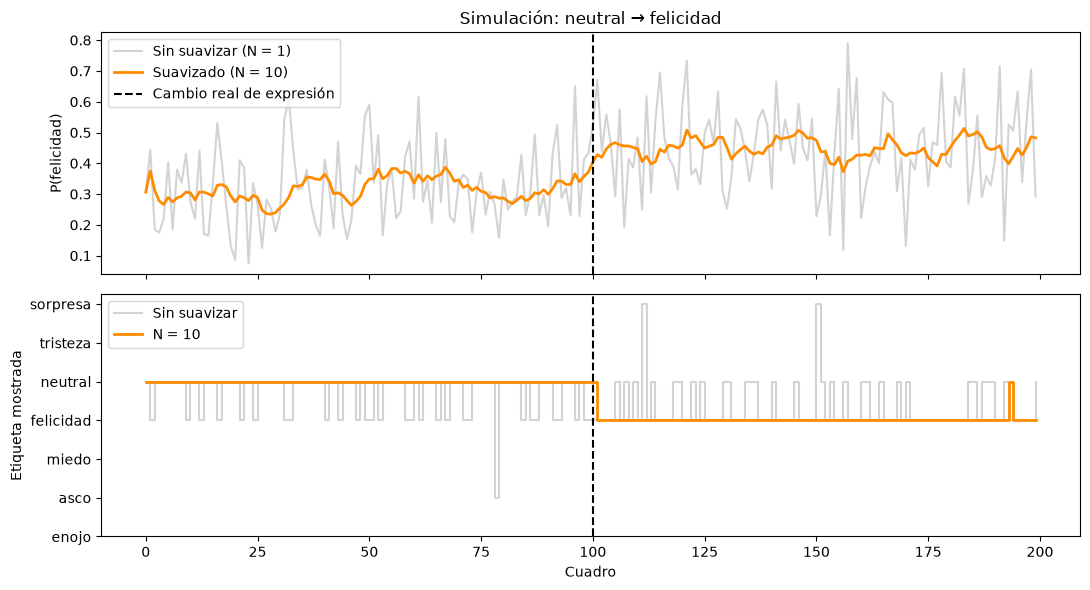

Guardado en reports/figures/smoothing_simulation.png


In [89]:
# --- Gráfica: probabilidad de "felicidad" y etiqueta mostrada, sin suavizar vs. N = 10 ---
labels_es = [EMOTION_LABELS_ES[c] for c in CLASS_NAMES]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax1.plot(raw_sequence[:, happy_idx], color="lightgray", label="Sin suavizar (N = 1)")
ax1.plot(simulated[SMOOTHING_WINDOW][0][:, happy_idx], color="darkorange", linewidth=2,
         label=f"Suavizado (N = {SMOOTHING_WINDOW})")
ax1.axvline(CHANGE_FRAME, color="black", linestyle="--", label="Cambio real de expresión")
ax1.set_ylabel("P(felicidad)")
ax1.legend(loc="upper left")
ax1.set_title("Simulación: neutral → felicidad")

ax2.step(range(N_FRAMES), simulated[1][1], where="post", color="lightgray", label="Sin suavizar")
ax2.step(range(N_FRAMES), simulated[SMOOTHING_WINDOW][1], where="post", color="darkorange", linewidth=2,
         label=f"N = {SMOOTHING_WINDOW}")
ax2.axvline(CHANGE_FRAME, color="black", linestyle="--")
ax2.set_yticks(range(len(CLASS_NAMES)))
ax2.set_yticklabels(labels_es)
ax2.set_xlabel("Cuadro")
ax2.set_ylabel("Etiqueta mostrada")
ax2.legend(loc="upper left")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "smoothing_simulation.png", dpi=120)
plt.show()
print("Guardado en reports/figures/smoothing_simulation.png")

### 4.2 Historial de emociones

El historial guarda **cómo se ha sentido la persona en el tiempo**. Lo usarán la interfaz (Fase 4, con una gráfica) y el asistente (Fase 5), para responder cosas como *"¿cómo me he sentido en el último minuto?"*.

**Decisiones de diseño:**
- Se guarda **una muestra por segundo** (`HISTORY_INTERVAL_S`), no una por cuadro: a 20 FPS serían 1.200 registros por minuto, casi todos repetidos. Cada muestra usa las probabilidades **ya suavizadas**.
- Se guardan como máximo **600 muestras (10 minutos)** en un `deque`; las más viejas se descartan solas.
- **Privacidad:** solo hay etiquetas, porcentajes y horas, **en memoria**. No se guardan imágenes ni se escribe el historial en disco; se borra al cerrar el notebook. Esto es lo que se enviará al asistente (Fase 5).

`summary()` resume el historial: la emoción **actual**, la **dominante** (la más frecuente) y la **distribución** (qué porcentaje del tiempo se registró cada emoción), para todo el historial o para los últimos N segundos.

In [90]:
HISTORY_INTERVAL_S = 1.0     # una muestra por segundo
HISTORY_MAX_ENTRIES = 600    # 10 minutos


class EmotionHistory:
    # Historial en memoria de las emociones (solo etiquetas y probabilidades, sin imágenes).

    def __init__(self, interval_s=HISTORY_INTERVAL_S, max_entries=HISTORY_MAX_ENTRIES):
        self.interval_s = interval_s
        self.entries = deque(maxlen=max_entries)
        self._last_time = None

    def add(self, probs, now=None):
        # Guarda una muestra si ya pasó el intervalo. Devuelve True si se guardó.
        now = time.time() if now is None else now
        if self._last_time is not None and now - self._last_time < self.interval_s:
            return False
        self._last_time = now
        index = int(np.argmax(probs))
        self.entries.append({
            "timestamp": now,
            "time": datetime.fromtimestamp(now).strftime("%H:%M:%S"),
            "emotion": CLASS_NAMES[index],
            "confidence": round(float(probs[index]), 4),
            "probabilities": {c: round(float(p), 4) for c, p in zip(CLASS_NAMES, probs)},
        })
        return True

    def summary(self, last_seconds=None):
        # Resume el historial completo o solo los últimos `last_seconds` segundos.
        entries = list(self.entries)
        if last_seconds is not None and entries:
            cutoff = entries[-1]["timestamp"] - last_seconds
            entries = [e for e in entries if e["timestamp"] > cutoff]
        if not entries:
            return {"samples": 0}
        counts = {c: 0 for c in CLASS_NAMES}
        for entry in entries:
            counts[entry["emotion"]] += 1
        dominant = max(counts, key=counts.get)
        return {
            "samples": len(entries),
            "seconds_covered": round(entries[-1]["timestamp"] - entries[0]["timestamp"] + self.interval_s, 1),
            "current_emotion": entries[-1]["emotion"],
            "current_confidence": entries[-1]["confidence"],
            "dominant_emotion": dominant,
            "distribution": {c: round(counts[c] / len(entries), 3) for c in CLASS_NAMES},
            "mean_confidence_dominant": round(float(np.mean(
                [e["confidence"] for e in entries if e["emotion"] == dominant])), 3),
        }

    def to_dataframe(self):
        # Tabla del historial (sin el detalle de las 7 probabilidades) para revisar o graficar.
        return pd.DataFrame([{k: v for k, v in e.items() if k != "probabilities"} for e in self.entries])

    def clear(self):
        self.entries.clear()
        self._last_time = None


# --- Prueba rápida con la simulación: 200 cuadros a 20 FPS = 10 s → deben quedar 10 muestras ---
test_history = EmotionHistory()
for frame_number, probs in enumerate(simulated[SMOOTHING_WINDOW][0]):
    test_history.add(probs, now=1_000_000 + frame_number / 20)
print(f"Muestras guardadas: {len(test_history.entries)} (esperado: 10)")
print("Resumen completo:      ", json.dumps(test_history.summary()["distribution"]))
print("Últimos 5 s, dominante:", test_history.summary(last_seconds=5)["dominant_emotion"])

Muestras guardadas: 10 (esperado: 10)
Resumen completo:       {"angry": 0.0, "disgust": 0.0, "fear": 0.0, "happy": 0.4, "neutral": 0.6, "sad": 0.0, "surprise": 0.0}
Últimos 5 s, dominante: happy


### 4.3 Demo completa en vivo: detección + suavizado + historial

Este es el **sistema completo de la Fase 3**. Respecto a la Parte 3:
- La etiqueta y el panel muestran las probabilidades **suavizadas**.
- Abajo del panel aparece la **emoción dominante de los últimos 30 segundos**, tomada del historial.
- Se registran las etiquetas **sin suavizar y suavizadas** de cada cuadro, para medir cuánto se redujo el parpadeo con datos reales.

Al salir, el historial queda en la variable `emotion_history` (en memoria) para revisarlo en la sección 4.4.

**Para probarlo bien:** alterna expresiones durante el minuto (neutral, sonrisa, sorpresa...) y gira un poco la cabeza en algún momento para ver el manejo del rostro perdido.

In [95]:
SUMMARY_WINDOW_S = 30   # ventana del resumen que se muestra en el panel


def draw_history_footer(panel, summary):
    # Escribe en la parte baja del panel la emoción dominante de los últimos segundos.
    if panel.shape[0] < 420:          # en videos muy bajos no hay espacio
        return panel
    y = panel.shape[0] - 20
    cv2.putText(panel, f"Ultimos {SUMMARY_WINDOW_S} s:", (15, y - 30), FONT, 0.55, (200, 200, 200), 1, cv2.LINE_AA)
    if summary.get("samples", 0) == 0:
        text = "--"
    else:
        dominant = summary["dominant_emotion"]
        text = f"{EMOTION_LABELS_ES[dominant]} {summary['distribution'][dominant]:.0%}"
    cv2.putText(panel, text, (15, y), FONT, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    return panel


def run_full_demo(max_seconds=MAX_SECONDS):
    # Demo en vivo con suavizado e historial. Devuelve (historial, estadísticas).
    cap = open_camera()
    if not cap.isOpened():
        raise RuntimeError(
            "No se pudo abrir la webcam. Cierra otras apps que la usen (Zoom, Teams, Cámara) "
            "y revisa Configuración → Privacidad y seguridad → Cámara."
        )

    smoother = EmotionSmoother()
    history = EmotionHistory()
    stats = {"frame_ms": [], "raw_labels": [], "smoothed_labels": [], "faces": []}
    predict_emotions_fast(np.zeros((1, FACE_SIZE, FACE_SIZE), dtype=np.float32))  # calentamiento
    cv2.namedWindow(WINDOW_NAME, cv2.WINDOW_NORMAL)

    fps = 0.0
    last_box = None
    start_time = last_time = time.perf_counter()
    try:
        while True:
            ok, frame_bgr = cap.read()
            if not ok:
                print("La cámara dejó de entregar imágenes.")
                break
            frame_bgr = cv2.flip(frame_bgr, 1)

            boxes, probs, _ = analyze_frame(frame_bgr, max_faces=1)   # solo el rostro principal
            n_detected = len(boxes)
            if boxes:
                smoothed = smoother.update(probs[0])
                history.add(smoothed)
                stats["raw_labels"].append(int(probs[0].argmax()))
                stats["smoothed_labels"].append(int(smoothed.argmax()))
                last_box = boxes[0]
                display_boxes, display_probs = boxes, smoothed[np.newaxis, :]
            else:
                smoother.mark_missing()
                held = smoother.current()
                if held is not None and last_box is not None:
                    # Pérdida breve del rostro: se mantiene la última caja y emoción (evita parpadeo)
                    display_boxes, display_probs = [last_box], held[np.newaxis, :]
                else:
                    display_boxes, display_probs = [], np.empty((0, len(CLASS_NAMES)))

            now = time.perf_counter()
            frame_ms = 1000 * (now - last_time)
            last_time = now
            current_fps = 1000 / max(frame_ms, 1e-6)
            fps = current_fps if fps == 0 else 0.9 * fps + 0.1 * current_fps
            stats["frame_ms"].append(frame_ms)
            stats["faces"].append(n_detected)

            annotated = draw_hud(draw_results(frame_bgr, display_boxes, display_probs), fps, n_detected)
            panel = draw_probability_panel(annotated.shape[0], display_probs[0] if len(display_probs) else None)
            panel = draw_history_footer(panel, history.summary(last_seconds=SUMMARY_WINDOW_S))
            cv2.imshow(WINDOW_NAME, np.hstack([annotated, panel]))

            key = cv2.waitKey(1) & 0xFF
            if key in (ord("q"), 27):
                break
            if cv2.getWindowProperty(WINDOW_NAME, cv2.WND_PROP_VISIBLE) < 1:
                break
            if max_seconds is not None and now - start_time > max_seconds:
                print(f"Se alcanzó el límite de {max_seconds} s.")
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()
        cv2.waitKey(1)
    return history, stats


print("Se abrirá una ventana con el video (puede quedar detrás del navegador).")
print("Para salir: selecciona la ventana del video y presiona q o Esc.")
emotion_history, full_demo_stats = run_full_demo(max_seconds=None)
print(f"Cuadros procesados: {len(full_demo_stats['frame_ms'])} | muestras en el historial: {len(emotion_history.entries)}")

Se abrirá una ventana con el video (puede quedar detrás del navegador).
Para salir: selecciona la ventana del video y presiona q o Esc.
Cuadros procesados: 1480 | muestras en el historial: 83


### 4.4 Resultados de la demo: estabilidad e historial

**Estabilidad:** comparamos cuántas veces cambió la etiqueta **sin suavizar** y **suavizada** en los mismos cuadros, normalizado a **cambios por cada 100 cuadros con rostro**. Un valor menor significa una etiqueta más estable y legible.

In [96]:
raw_changes = count_label_changes(full_demo_stats["raw_labels"])
smoothed_changes = count_label_changes(full_demo_stats["smoothed_labels"])
frames_with_face = len(full_demo_stats["raw_labels"])
frame_ms = np.array(full_demo_stats["frame_ms"][10:], dtype=float)

if frames_with_face < 2:
    print("Se detectaron muy pocos cuadros con rostro: repite la demo con más luz y de frente a la cámara.")
else:
    stability = {
        "frames_with_face": frames_with_face,
        "smoothing_window": SMOOTHING_WINDOW,
        "raw_label_changes": raw_changes,
        "smoothed_label_changes": smoothed_changes,
        "raw_changes_per_100_frames": round(100 * raw_changes / frames_with_face, 2),
        "smoothed_changes_per_100_frames": round(100 * smoothed_changes / frames_with_face, 2),
        "flicker_reduction_pct": round(100 * (1 - smoothed_changes / raw_changes), 1) if raw_changes else None,
        "avg_fps": round(1000 / frame_ms.mean(), 1) if len(frame_ms) else None,
        "history_samples": len(emotion_history.entries),
    }
    with open(METRICS_DIR / "smoothing_stability.json", "w", encoding="utf-8") as f:
        json.dump(stability, f, indent=2)
    print(json.dumps(stability, indent=2))
    print("Guardado en reports/metrics/smoothing_stability.json (solo números, sin el historial)")

{
  "frames_with_face": 1258,
  "smoothing_window": 10,
  "raw_label_changes": 189,
  "smoothed_label_changes": 63,
  "raw_changes_per_100_frames": 15.02,
  "smoothed_changes_per_100_frames": 5.01,
  "flicker_reduction_pct": 66.7,
  "avg_fps": 16.2,
  "history_samples": 83
}
Guardado en reports/metrics/smoothing_stability.json (solo números, sin el historial)


In [97]:
# --- Resumen del historial (es lo que recibirá el asistente en la Fase 5) ---
print("Toda la sesión:")
print(json.dumps(emotion_history.summary(), indent=2, ensure_ascii=False))
print(f"\nÚltimos {SUMMARY_WINDOW_S} s:")
print(json.dumps(emotion_history.summary(last_seconds=SUMMARY_WINDOW_S), indent=2, ensure_ascii=False))

Toda la sesión:
{
  "samples": 83,
  "seconds_covered": 91.8,
  "current_emotion": "neutral",
  "current_confidence": 0.6649,
  "dominant_emotion": "neutral",
  "distribution": {
    "angry": 0.084,
    "disgust": 0.024,
    "fear": 0.169,
    "happy": 0.072,
    "neutral": 0.325,
    "sad": 0.253,
    "surprise": 0.072
  },
  "mean_confidence_dominant": 0.586
}

Últimos 30 s:
{
  "samples": 24,
  "seconds_covered": 30.3,
  "current_emotion": "neutral",
  "current_confidence": 0.6649,
  "dominant_emotion": "sad",
  "distribution": {
    "angry": 0.083,
    "disgust": 0.083,
    "fear": 0.0,
    "happy": 0.125,
    "neutral": 0.292,
    "sad": 0.375,
    "surprise": 0.042
  },
  "mean_confidence_dominant": 0.513
}


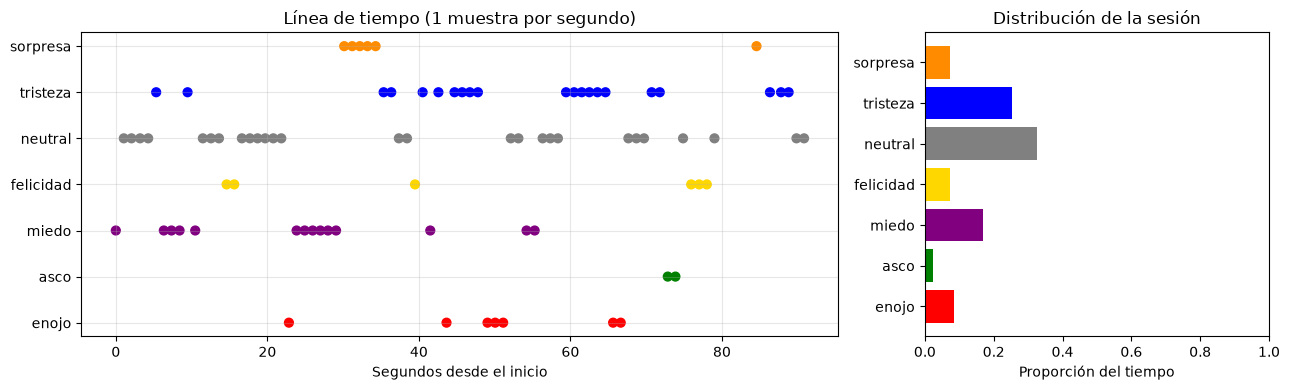

Guardado en reports/figures/emotion_history_demo.png (solo etiquetas, sin imágenes de la cámara)


,time,emotion,confidence
73,20:09:22,happy,0.5957
74,20:09:23,happy,0.5661
75,20:09:24,happy,0.5147
76,20:09:25,neutral,0.8804
77,20:09:31,surprise,0.3525
78,20:09:33,sad,0.9153
79,20:09:34,sad,0.6282
80,20:09:35,sad,0.4493
81,20:09:36,neutral,0.5290
82,20:09:37,neutral,0.6649


In [98]:
# --- Gráficas del historial: línea de tiempo y distribución ---
history_df = emotion_history.to_dataframe()
if history_df.empty:
    print("El historial está vacío: no se detectó ningún rostro durante la demo.")
else:
    history_df["elapsed_s"] = history_df["timestamp"] - history_df["timestamp"].iloc[0]
    history_df["emotion_index"] = history_df["emotion"].map(CLASS_NAMES.index)
    # Colores de OpenCV (BGR, 0-255) → Matplotlib (RGB, 0-1)
    rgb_colors = {c: tuple(v / 255 for v in reversed(EMOTION_COLORS[c])) for c in CLASS_NAMES}
    rgb_colors["neutral"] = (0.5, 0.5, 0.5)   # el gris claro casi no se ve sobre fondo blanco

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2.2, 1]})
    ax1.scatter(history_df["elapsed_s"], history_df["emotion_index"],
                c=[rgb_colors[e] for e in history_df["emotion"]], s=40)
    ax1.set_yticks(range(len(CLASS_NAMES)))
    ax1.set_yticklabels(labels_es)
    ax1.set_xlabel("Segundos desde el inicio")
    ax1.set_title("Línea de tiempo (1 muestra por segundo)")
    ax1.grid(alpha=0.3)

    distribution = emotion_history.summary()["distribution"]
    ax2.barh(labels_es, [distribution[c] for c in CLASS_NAMES], color=[rgb_colors[c] for c in CLASS_NAMES])
    ax2.set_xlim(0, 1)
    ax2.set_xlabel("Proporción del tiempo")
    ax2.set_title("Distribución de la sesión")
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "reports" / "figures" / "emotion_history_demo.png", dpi=120)
    plt.show()
    print("Guardado en reports/figures/emotion_history_demo.png (solo etiquetas, sin imágenes de la cámara)")
    display(history_df[["time", "emotion", "confidence"]].tail(10))

### Evidencias de la Parte 4 para el reporte
- Tabla y gráfica de la **simulación** (`reports/metrics/smoothing_simulation.csv` y `reports/figures/smoothing_simulation.png`): justifican la ventana `N = 10` con el compromiso estabilidad vs. retraso.
- `reports/metrics/smoothing_stability.json`: **reducción real del parpadeo** con la webcam.
- `reports/figures/emotion_history_demo.png`: línea de tiempo y distribución del historial.
- Capturas de la ventana en vivo mostrando el panel con **"Últimos 30 s"**, y un fragmento grabado para el video.
- Ninguna de estas evidencias contiene imágenes de la cámara, así que se pueden subir a GitHub.